In [4]:
from google.colab import drive
drive.mount('/content/drive')

#  Set path to your dataset ZIP file in Drive
zip_path = "/content/drive/MyDrive/Brain_Tumor_Dataset.zip"

# Unzip it into /content directory
import zipfile, os

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/Brain_Tumor_Dataset")

print("Dataset extracted to /content/Brain_Tumor_Dataset")

# Check folder structure
!ls /content/Brain_Tumor_Dataset
!ls /content/Brain_Tumor_Dataset/Training

Mounted at /content/drive
Dataset extracted to /content/Brain_Tumor_Dataset
Testing  Training
glioma_tumor  meningioma_tumor	no_tumor  pituitary_tumor


In [36]:
# Brain Tumor MRI Classification - DenseNet121
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [37]:
# Dataset Paths
base_dir = "/content/Brain_Tumor_Dataset"
train_dir = os.path.join(base_dir, "Training")
test_dir = os.path.join(base_dir, "Testing")

# Parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 12
LR = 1e-4


In [38]:
# Data Augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=[0.8,1.2],
    validation_split=0.2
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset='training',
    class_mode='categorical',
    shuffle=True
)

val_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset='validation',
    class_mode='categorical',
    shuffle=False
)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    class_mode='categorical'
)


Found 2297 images belonging to 4 classes.
Found 573 images belonging to 4 classes.
Found 394 images belonging to 4 classes.


In [39]:

# Class Weights (to handle imbalance)
classes = list(train_gen.class_indices.keys())
y_train = train_gen.classes
class_weights_values = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
class_weights = dict(enumerate(class_weights_values))
print("Class Weights:", class_weights)


# Model: DenseNet121
base_model = DenseNet121(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Freeze initial layers
for layer in base_model.layers[:-100]:  # unfreeze last 100 layers
    layer.trainable = False
for layer in base_model.layers[-100:]:
    layer.trainable = True

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.2)(x)
predictions = Dense(len(classes), activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

model.compile(optimizer=Adam(learning_rate=LR), loss='categorical_crossentropy', metrics=['accuracy'])

model.summary()


# Callbacks: EarlyStopping + ReduceLR
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)

Class Weights: {0: np.float64(0.8687594553706506), 1: np.float64(0.8727203647416414), 2: np.float64(1.817246835443038), 3: np.float64(0.8674471299093656)}


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_8    │ (None, 230, 230,  │          0 │ input_layer_4[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d_8… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_9    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_9… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

 Total params: 7,300,932 (27.85 MB)

 Trainable params: 2,212,036 (8.44 MB)

 Non-trainable params: 5,088,896 (19.41 MB)

In [40]:
#  Train the Model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr]
)



/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/12
72/72 ━━━━━━━━━━━━━━━━━━━━ 156s 1s/step - accuracy: 0.4752 - loss: 1.2473 - val_accuracy: 0.6073 - val_loss: 0.9349 - learning_rate: 1.0000e-04
Epoch 2/12
72/72 ━━━━━━━━━━━━━━━━━━━━ 43s 595ms/step - accuracy: 0.7714 - loss: 0.6027 - val_accuracy: 0.7138 - val_loss: 0.7002 - learning_rate: 1.0000e-04
Epoch 3/12
72/72 ━━━━━━━━━━━━━━━━━━━━ 44s 615ms/step - accuracy: 0.8340 - loss: 0.4454 - val_accuracy: 0.7976 - val_loss: 0.5371 - learning_rate: 1.0000e-04
Epoch 4/12
72/72 ━━━━━━━━━━━━━━━━━━━━ 46s 641ms/step - accuracy: 0.8598 - loss: 0.3574 - val_accuracy: 0.8272 - val_loss: 0.4789 - learning_rate: 1.0000e-04
Epoch 5/12
72/72 ━━━━━━━━━━━━━━━━━━━━ 46s 640ms/step - accuracy: 0.8799 - loss: 0.3168 - val_accuracy: 0.8220 - val_loss: 0.4593 - learning_rate: 1.0000e-04
Epoch 6/12
72/72 ━━━━━━━━━━━━━━━━━━━━ 45s 625ms/step - accuracy: 0.8827 - loss: 0.3119 - val_accuracy: 0.8656 - val_loss: 0.3927 - learning_rate: 1.0000e-04
Epoch 7/12
72/72 ━━━━━━━━━━━━━━━━━━━━ 46s 638ms/step - accur

In [41]:
# Evaluate on Test Data
test_loss, test_acc = model.evaluate(test_gen)
print(f"\n Test Accuracy: {test_acc*100:.2f}%")


13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 803ms/step - accuracy: 0.5729 - loss: 2.2232

 Test Accuracy: 72.84%


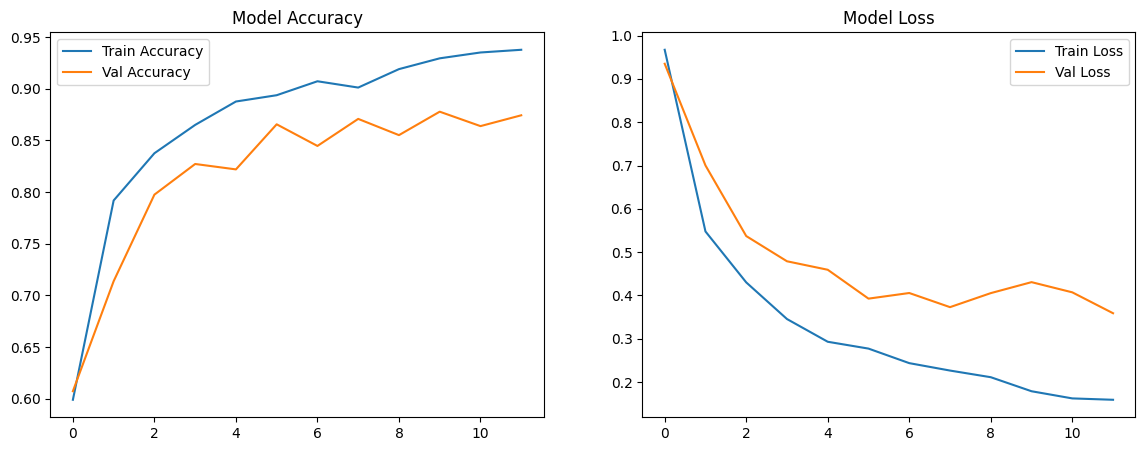

In [42]:
#  Visualization: Accuracy & Loss
plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title('Model Accuracy')

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Model Loss')
plt.show()



In [44]:
# Save the model in native Keras format
model.save("/content/drive/MyDrive/BrainTumor_DenseNet121.keras")
print(" Model saved as BrainTumor_DenseNet121.keras")

 Model saved as BrainTumor_DenseNet121.keras


Test

In [45]:
# Upload and Test Single Brain MRI Image
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import numpy as np
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt



In [52]:
# Load Saved Model
model = load_model("/content/drive/MyDrive/BrainTumor_DenseNet121.keras")
print("✅ Model loaded successfully!")


# Upload Image
uploaded = files.upload()  # Upload an image file

for fn in uploaded.keys():
    img_path = fn

✅ Model loaded successfully!


Saving image(34).jpg to image(34).jpg


In [53]:
# Preprocess Image
IMG_SIZE = (224, 224)  # Must match training image size

img = Image.open(img_path).convert('RGB')
img = img.resize(IMG_SIZE)
img_array = np.array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)  # Shape: (1, 224, 224, 3)


# Make Prediction
pred = model.predict(img_array)
class_idx = np.argmax(pred)
class_labels = ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']
predicted_class = class_labels[class_idx]

1/1 ━━━━━━━━━━━━━━━━━━━━ 11s 11s/step


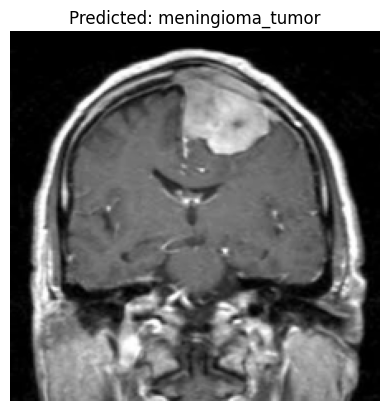

✅ Predicted class: meningioma_tumor


In [54]:
# Show Image & Prediction
plt.imshow(img)
plt.title(f"Predicted: {predicted_class}")
plt.axis('off')
plt.show()

print(f"✅ Predicted class: {predicted_class}")